# Deteksi Lubang Jalan · YOLOv8s · Skema A & B · Dataset Kaggle

Notebook ini menjalankan run **#1 dan #2** di tabel percobaan secara berurutan: `yolov8s.pt` dengan **Skema A** (augmentasi bawaan YOLO), lalu **Skema B** (augmentasi bawaan + kecerahan, kontras, silau, dan bayangan via Albumentations). Dataset diunduh dan dibersihkan sekali, lalu dipakai bersama oleh kedua skema. Pipeline data, cleaning, hyperparameter, dan evaluasi sama persis dengan notebook YOLO11s Skema A.

Dua run butuh waktu kira-kira dua kali lipat satu run. Kalau sesi Colab terputus, cukup **Run all** lagi: skema yang sudah selesai dilewati, dan skema yang terputus dilanjutkan dari `last.pt`.

Pilih **runtime GPU → Run all**, lalu izinkan akses Google Drive. Pada penggunaan pertama, notebook mengambil dataset dari Kaggle dan membuat ZIP cache di Drive. Sesi Colab berikutnya memakai ZIP tersebut. Kalau sudah punya ZIP sendiri, isi `DATA_ZIP` dengan path-nya di sel konfigurasi.

Notebook melatih satu kelas, yaitu **pothole**. Split train, validation, dan test bawaan dipertahankan setelah cleaning dan deduplikasi. Bila sumber tidak menyediakan test, sebagian kelompok foto train disisihkan. Fine-tuning dimulai dari `yolov8s.pt` dan evaluasi memakai `best.pt`. Setiap skema punya folder run sendiri; checkpoint dan metrik tersimpan di `MyDrive/deteksi-jalan/hasil/yolo_kaggle_pothole/<RUN_NAME>/`.

[Dataset Kaggle](https://www.kaggle.com/datasets/muskanverma24/pothole-detection-dataset-yolov11-optimized) · [KaggleHub](https://github.com/Kaggle/kagglehub) · [Panduan training Ultralytics](https://docs.ultralytics.com/modes/train/)


In [2]:
# 0 · Pustaka Colab. PyTorch dan CUDA mengikuti runtime yang sudah tersedia.
import importlib.util
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

ULTRALYTICS_VERSION = '8.4.202'
try:
    installed_yolo = version('ultralytics')
except PackageNotFoundError:
    installed_yolo = None
packages = []
if installed_yolo != ULTRALYTICS_VERSION:
    packages.append(f'ultralytics=={ULTRALYTICS_VERSION}')
for module, package in [('kagglehub', 'kagglehub'), ('scipy', 'scipy'), ('albumentations', 'albumentations')]:
    if importlib.util.find_spec(module) is None:
        packages.append(package)
if packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *packages])


In [3]:
# 1 · Import dan verifikasi GPU
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from datetime import datetime
from itertools import chain
import hashlib
import json
import os
import random
import re
import shutil
import tempfile
import warnings
import zipfile

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image
from scipy.fft import dctn
from scipy.ndimage import laplace
from tqdm.auto import tqdm
import torch
import ultralytics
from ultralytics import YOLO
import yaml

if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError('Versi Ultralytics lama sudah diimpor. Restart runtime dan jalankan dari awal.')
if not torch.cuda.is_available():
    raise RuntimeError('Pilih runtime GPU di Colab untuk training YOLO.')
DEVICE = 0
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('GPU:', torch.cuda.get_device_name(DEVICE))
print('PyTorch:', torch.__version__, '| Ultralytics:', ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
PyTorch: 2.14.1+cu130 | Ultralytics: 8.4.202


In [4]:
# Konfigurasi Colab dan Google Drive.
from google.colab import drive
drive.mount('/content/drive')

DATASET = 'muskanverma24/pothole-detection-dataset-yolov11-optimized'
DATA_ZIP = None  # Opsional. Contoh: '/content/drive/MyDrive/Dataset/pothole.zip'
DATA_YAML_REL = None  # Isi path relatif ke dalam ZIP jika terdeteksi beberapa YAML.
VERIFIED_BACKGROUND_CSV = None  # Opsional, kolom source_image dari cleaning_audit.csv.
WORK_DIR = Path('/content/deteksi-jalan/pothole_kaggle')
WORK_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/deteksi-jalan')
CACHE_ZIP = DRIVE_PROJECT_DIR / 'data' / 'kaggle_pothole_yolov11.zip'

MODEL = 'yolov8s.pt'
SKEMA_LIST = ['A', 'B']  # A = augmentasi standar, B = ditambah augmentasi cuaca. Dijalankan berurutan.
RUN_SUFFIX = '01'  # Ganti, misalnya '02', untuk mengulang percobaan dari nol tanpa menimpa hasil lama.
IMG_SIZE = 640
BATCH_SIZE = 8
EPOCHS = 45
PATIENCE = 10
WORKERS = 2
CLOSE_MOSAIC = 5
PREDICT_CONF = 0.25

SPLITS = ('train', 'val', 'test')
CLASS_NAMES = ['pothole']
KEEP_PRIORITY = {'test': 0, 'val': 1, 'train': 2}
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
MIN_SIDE = 32
BOX_TOLERANCE = 1e-6
PHASH_DISTANCE = 4
PHASH_MAX_MAE = 12.0

RUN_NAMES = {skema: f'{Path(MODEL).stem}_{skema}_kaggle_pothole_{RUN_SUFFIX}' for skema in SKEMA_LIST}
if not SKEMA_LIST or len(set(SKEMA_LIST)) != len(SKEMA_LIST) or not set(SKEMA_LIST) <= {'A', 'B'}:
    raise ValueError("Isi SKEMA_LIST dengan 'A' dan/atau 'B', tanpa duplikat.")
if not all(re.fullmatch(r'[A-Za-z0-9_-]+', name) for name in RUN_NAMES.values()):
    raise ValueError('RUN_SUFFIX hanya boleh berisi huruf, angka, garis bawah, atau tanda hubung.')
RUNS_ROOT = DRIVE_PROJECT_DIR / 'hasil' / 'yolo_kaggle_pothole'


def run_paths(skema):
    split_dir = RUNS_ROOT / RUN_NAMES[skema]
    return split_dir, split_dir / 'weights' / 'best.pt', split_dir / 'weights' / 'last.pt'


def run_done(skema):
    split_dir = run_paths(skema)[0]
    return (split_dir / 'metrics.csv').is_file() and (split_dir / 'predictions_test.csv').is_file()


for skema in SKEMA_LIST:
    split_dir, best_path, last_path = run_paths(skema)
    if run_done(skema):
        status = 'sudah selesai, akan dilewati'
    elif last_path.is_file():
        status = 'belum selesai, akan dilanjutkan dari last.pt'
    else:
        status = 'baru'
    print(f'Skema {skema}: {RUN_NAMES[skema]} ({status})')


Mounted at /content/drive
Skema A: yolov8s_A_kaggle_pothole_01 (sudah selesai, akan dilewati)
Skema B: yolov8s_B_kaggle_pothole_01 (sudah selesai, akan dilewati)


## 1. Unduh dataset sekali dan pakai cache Drive

Secara default, sumber adalah `kaggle_pothole_yolov11.zip` di folder `MyDrive/deteksi-jalan/data/`. File baru diterbitkan setelah unduhan selesai dan struktur split bisa dibaca. `DATA_ZIP` bisa diarahkan ke ZIP manual jika akses Kaggle membutuhkan login atau unduh otomatis gagal.


In [5]:
downloaded_now = False
if DATA_ZIP is not None or CACHE_ZIP.is_file():
    source_zip = Path(DATA_ZIP).expanduser() if DATA_ZIP is not None else CACHE_ZIP
    if not zipfile.is_zipfile(source_zip):
        raise ValueError(f'ZIP dataset tidak dapat dibaca: {source_zip}')
    source_dir = Path(tempfile.mkdtemp(prefix='source_', dir=WORK_DIR))
    with zipfile.ZipFile(source_zip) as archive:
        seen = set()
        for member in archive.infolist():
            path = PurePosixPath(member.filename)
            if path.is_absolute() or '..' in path.parts or chr(92) in member.filename or path in seen:
                raise ValueError(f'Nama file ZIP tidak aman atau duplikat: {member.filename}')
            seen.add(path)
        archive.extractall(source_dir)
    print('Membaca dataset dari ZIP:', source_zip)
else:
    import kagglehub

    try:
        source_dir = Path(kagglehub.dataset_download(DATASET)).resolve()
    except Exception as error:
        raise RuntimeError('Unduh Kaggle gagal. Simpan ZIP dataset di Drive dan isi DATA_ZIP.') from error
    downloaded_now = True

source_dir = source_dir.resolve()
yaml_paths = [source_dir / DATA_YAML_REL] if DATA_YAML_REL else sorted(
    [*source_dir.rglob('*.yaml'), *source_dir.rglob('*.yml')]
)
candidates = []
for path in yaml_paths:
    path = path.resolve()
    if not path.is_relative_to(source_dir) or not path.is_file():
        raise ValueError(f'Path YAML dataset tidak ditemukan di sumber: {path}')
    config = yaml.safe_load(path.read_text(encoding='utf-8-sig'))
    if not isinstance(config, dict) or 'train' not in config:
        continue
    names = config.get('names')
    if isinstance(names, list):
        names = dict(enumerate(names))
    if not isinstance(names, dict):
        continue
    names = {int(i): str(name) for i, name in names.items()}
    ids = {i for i, name in names.items() if name.strip().lower() in {'pothole', 'potholes'}}
    if ids:
        candidates.append((path, config, names, ids))

if len(candidates) != 1:
    raise ValueError(f'Perlu satu YAML deteksi pothole. Pilihan: {[x[0] for x in candidates]}. Isi DATA_YAML_REL.')
source_yaml, config, label_map, pothole_ids = candidates[0]
root = source_yaml.parent


def resolve_source_path(value, bases):
    raw = Path(str(value).replace(chr(92), '/'))
    alternatives = [raw]
    if raw.parts and raw.parts[0] == '..':
        alternatives.append(Path(*[part for part in raw.parts if part != '..']))
    for base in bases:
        for relative in alternatives:
            path = (base / relative).resolve()
            if path.is_relative_to(source_dir) and path.exists():
                return path
    return None


def load_split(split):
    aliases = ('val', 'valid', 'validation') if split == 'val' else (split,)
    entries = next((config[key] for key in aliases if config.get(key)), None)
    base = resolve_source_path(config.get('path') or '.', [root, source_dir])
    bases = [base, root] if base and base.is_dir() else [root]
    if entries is None:
        entries = next((str(path) for alias in aliases
                        for path in (root / alias / 'images', root / 'images' / alias)
                        if path.is_dir()), None)
        if entries is None and split == 'test':
            return None
    if not isinstance(entries, (str, list)):
        raise ValueError(f'Konfigurasi split tidak valid: {split}')
    images = set()
    for entry in ([entries] if isinstance(entries, str) else entries):
        path = resolve_source_path(entry, bases)
        if path is None:
            raise FileNotFoundError(f'Path split {split} tidak ditemukan: {entry}')
        if path.is_dir():
            images.update(p for p in path.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        elif path.suffix.lower() == '.txt':
            for line in path.read_text(encoding='utf-8-sig').splitlines():
                if not line.strip():
                    continue
                image = resolve_source_path(line.strip(), [path.parent, *bases])
                if image is None or not image.is_file() or image.suffix.lower() not in IMAGE_EXTS:
                    raise FileNotFoundError(f'Gambar di daftar split {split} tidak ditemukan: {line}')
                images.add(image)
        elif path.suffix.lower() in IMAGE_EXTS:
            images.add(path)
        else:
            raise ValueError(f'Format split {split} tidak didukung: {path}')
    if not images:
        raise ValueError(f'Split {split} tidak memiliki gambar.')
    return sorted(images)


source_splits = {part: load_split(part) for part in SPLITS}
if downloaded_now:
    CACHE_ZIP.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='.pothole_cache_', dir=CACHE_ZIP.parent) as temporary:
        pending = Path(temporary) / CACHE_ZIP.name
        with zipfile.ZipFile(pending, 'w', compression=zipfile.ZIP_STORED, allowZip64=True) as archive:
            for path in sorted(source_dir.rglob('*')):
                if path.is_file():
                    archive.write(path, path.relative_to(source_dir))
        pending.replace(CACHE_ZIP)
    print('Cache dataset tersimpan di Drive:', CACHE_ZIP)

print('Konfigurasi sumber:', source_yaml)
print('Pemetaan kelas sumber:', label_map)
print('Jumlah gambar sumber:', {split: len(paths or []) for split, paths in source_splits.items()})


Membaca dataset dari ZIP: /content/drive/MyDrive/deteksi-jalan/data/kaggle_pothole_yolov11.zip
Konfigurasi sumber: /content/deteksi-jalan/pothole_kaggle/source_swzineaw/data.yaml
Pemetaan kelas sumber: {0: 'pothole'}
Jumlah gambar sumber: {'train': 3345, 'val': 397, 'test': 198}


## 2. Cleaning gambar dan anotasi

Notebook membaca kelas dari YAML sumber dan menulis ulang ID pothole sebagai 0. Foto rusak, kotak yang invalid, dan gambar duplikat dikeluarkan. Foto yang cuma berlabel kelas lain dikeluarkan. Jika foto memiliki pothole sekaligus kelas lain, kotak pothole dipertahankan. File label kosong hanya diterima jika foto bebas lubang dan path sumbernya sudah dimasukkan ke daftar background terverifikasi. Foto mirip lintas split dicatat untuk review.


In [6]:
def inspect_label(path):
    if not path.is_file():
        raise ValueError('missing_label')

    boxes = set()
    duplicates = 0
    adjusted = 0
    for line_no, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip():
            continue
        try:
            cls, *values = line.split()
            cls = int(cls)
            cx, cy, width, height = map(float, values)
            if cls not in label_map or not np.isfinite([cx, cy, width, height]).all():
                raise ValueError('ID kelas atau koordinat tidak valid')
            if min(width, height) <= 0:
                raise ValueError('lebar atau tinggi tidak positif')

            left, right = cx - width / 2, cx + width / 2
            top, bottom = cy - height / 2, cy + height / 2
            if min(left, top) < -BOX_TOLERANCE or max(right, bottom) > 1 + BOX_TOLERANCE:
                raise ValueError('bounding box keluar dari gambar')
            if min(left, top) < 0 or max(right, bottom) > 1:
                left, right = max(0, left), min(1, right)
                top, bottom = max(0, top), min(1, bottom)
                cx, cy = (left + right) / 2, (top + bottom) / 2
                width, height = right - left, bottom - top
                adjusted += 1
            if min(width, height) <= 0:
                raise ValueError('bounding box kosong setelah validasi')
        except (ValueError, OverflowError) as error:
            raise ValueError(f'invalid_label | baris {line_no} | {error}') from error

        # Format numerik yang berbeda untuk box yang sama menghasilkan tuple yang sama.
        box = (cls, cx, cy, width, height)
        duplicates += box in boxes
        boxes.add(box)
    return tuple(sorted(boxes)), duplicates, adjusted


def rgb_image(image):
    if 'A' in image.getbands() or 'transparency' in image.info:
        rgba = image.convert('RGBA')
        background = Image.new('RGBA', rgba.size, (128, 128, 128, 255))
        return Image.alpha_composite(background, rgba).convert('RGB')
    return image.convert('RGB')


def inspect_image(path):
    with warnings.catch_warnings():
        warnings.simplefilter('error', Image.DecompressionBombWarning)
        with Image.open(path) as image:
            if image.getexif().get(274, 1) != 1:
                raise ValueError('exif_orientation_review')
            if getattr(image, 'n_frames', 1) != 1:
                raise ValueError('multiframe_image')
            if min(image.size) < MIN_SIDE:
                raise ValueError('image_too_small')
            has_alpha = 'A' in image.getbands() or 'transparency' in image.info
            rgb = rgb_image(image)
            if all(low == high for low, high in rgb.getextrema()):
                raise ValueError('uniform_image')

            gray = rgb.convert('L')
            thumbnail = np.asarray(gray.resize((32, 32), Image.Resampling.LANCZOS), dtype=np.uint8)
            coeffs = dctn(thumbnail.astype(np.float32), norm='ortho')[:8, :8].ravel()[1:]
            bits = (coeffs > np.median(coeffs)).astype(np.uint8)
            perceptual_hash = int.from_bytes(np.packbits(bits).tobytes(), 'big') >> 1

            gray.thumbnail((256, 256), Image.Resampling.LANCZOS)
            pixels = np.asarray(gray, dtype=np.float32)
            brightness = float(pixels.mean())
            sharpness = float(laplace(pixels).var())

            flags = []
            if brightness < 35:
                flags.append('dark')
            if brightness > 225:
                flags.append('bright')
            if sharpness < 25:
                flags.append('low_sharpness')
            if min(image.size) < 256:
                flags.append('low_resolution')
            if has_alpha:
                flags.append('transparency_composited')

            copy_original = (
                image.mode == 'RGB' and not has_alpha
                and ((image.format == 'JPEG' and path.suffix.lower() in {'.jpg', '.jpeg'})
                     or (image.format == 'PNG' and path.suffix.lower() == '.png'))
            )
            digest = hashlib.sha256(f'{rgb.width}x{rgb.height}:'.encode())
            digest.update(rgb.tobytes())
            return {
                'width': rgb.width, 'height': rgb.height,
                'format_source': image.format, 'mode_source': image.mode,
                'brightness': brightness, 'sharpness': sharpness, 'quality_flags': '|'.join(flags),
                'pixel_sha256': digest.hexdigest(), 'phash': perceptual_hash,
                'thumbnail': thumbnail, 'copy_original': copy_original,
            }


In [7]:
def image_label_path(image):
    parts = list(image.parts)
    if 'images' not in parts:
        raise ValueError('struktur images/labels tidak ditemukan')
    index = len(parts) - 1 - parts[::-1].index('images')
    parts[index] = 'labels'
    return Path(*parts).with_suffix('.txt')


approved = set()
if VERIFIED_BACKGROUND_CSV:
    reviews = pd.read_csv(VERIFIED_BACKGROUND_CSV, dtype=str, keep_default_na=False)
    approved = set(reviews['source_image'].str.strip()) - {''}

records = []
for split, paths in source_splits.items():
    for image in tqdm(paths or [], desc=f'Cleaning {split}', unit='foto'):
        source_image = image.relative_to(source_dir).as_posix()
        record = dict(split=split, source_image=source_image, source_path=image,
                      status='keep', reason='', detail='')
        try:
            boxes, duplicates, adjusted = inspect_label(image_label_path(image))
            selected_boxes = tuple(sorted({(0, *box[1:]) for box in boxes if box[0] in pothole_ids}))
            record.update(boxes=selected_boxes, duplicate_boxes=duplicates, adjusted_boxes=adjusted)
            if not boxes and source_image not in approved:
                record.update(status='excluded', reason='unverified_empty_label')
            elif boxes and not selected_boxes:
                record.update(status='excluded', reason='no_pothole_box')
            else:
                record.update(inspect_image(image))
        except (OSError, ValueError, SyntaxError, OverflowError,
                Image.DecompressionBombError, Image.DecompressionBombWarning) as error:
            record.update(status='excluded', reason='invalid_image_or_label', detail=str(error))
        records.append(record)

exact_groups = defaultdict(list)
for record in records:
    if record['status'] == 'keep':
        exact_groups[record['pixel_sha256']].append(record)
for copies in exact_groups.values():
    if len({record['boxes'] for record in copies}) > 1:
        for record in copies:
            record.update(status='excluded', reason='duplicate_label_conflict')
        continue
    copies.sort(key=lambda row: (KEEP_PRIORITY[row['split']], row['source_image']))
    for record in copies[1:]:
        record.update(status='excluded', reason='exact_duplicate', detail=copies[0]['source_image'])

kept = [record for record in records if record['status'] == 'keep']
SPLIT = 'kaggle_original'
if source_splits['test'] is None:
    # Kelompokkan versi gambar dengan nama Roboflow yang sama sebelum menyisihkan test.
    groups = defaultdict(list)
    for record in kept:
        if record['split'] == 'train':
            group = re.sub(r'\.rf\.[0-9a-f]+$', '', record['source_path'].stem, flags=re.IGNORECASE)
            groups[group].append(record)
    if len(groups) < 2:
        raise ValueError('Train harus memiliki minimal dua kelompok untuk membuat test set.')
    shuffled = sorted(groups)
    random.Random(SEED).shuffle(shuffled)
    target = max(1, round(sum(map(len, groups.values())) * 0.15))
    moved = 0
    for group in shuffled[:-1]:
        for record in groups[group]:
            record['split'] = 'test'
        moved += len(groups[group])
        if moved >= target:
            break
    SPLIT = 'kaggle_with_train_holdout'
    print('Test bawaan tidak tersedia. Sebagian kelompok train disisihkan sebagai test.')

if not kept or any(not any(row['split'] == split and row['boxes'] for row in kept) for split in SPLITS):
    raise ValueError('Setiap split harus memiliki setidaknya satu gambar dengan kotak pothole setelah cleaning.')


Cleaning train:   0%|          | 0/3345 [00:00<?, ?foto/s]

Cleaning val:   0%|          | 0/397 [00:00<?, ?foto/s]

Cleaning test:   0%|          | 0/198 [00:00<?, ?foto/s]

In [8]:
def hash_bands(value):
    # Lima bagian untuk jarak maksimum empat bit: minimal satu bagian pasti sama.
    for band, start in enumerate(range(0, 63, 13)):
        yield band, (value >> start) & ((1 << min(13, 63 - start)) - 1)


buckets = defaultdict(list)
near_duplicates = []
if not 0 <= PHASH_DISTANCE <= 4:
    raise ValueError('PHASH_DISTANCE harus di antara 0 dan 4 untuk indeks lima bagian.')

for index, current in enumerate(kept):
    bands = tuple(hash_bands(current['phash']))
    matches = set(chain.from_iterable(buckets[band] for band in bands))
    for other_index in sorted(matches):
        other = kept[other_index]
        if current['split'] == other['split']:
            continue
        distance = (current['phash'] ^ other['phash']).bit_count()
        if distance > PHASH_DISTANCE:
            continue
        aspect_ratio = (current['width'] * other['height']) / (current['height'] * other['width'])
        if not 0.95 <= aspect_ratio <= 1.05:
            continue
        difference = np.abs(current['thumbnail'].astype(np.int16) - other['thumbnail']).mean()
        if difference <= PHASH_MAX_MAE:
            near_duplicates.append({
                'image_a': other['source_image'], 'split_a': other['split'],
                'image_b': current['source_image'], 'split_b': current['split'],
                'phash_distance': distance, 'thumbnail_mae': round(float(difference), 3),
            })
    for band in bands:
        buckets[band].append(index)

print(f'Gambar lolos: {len(kept):,} dari {len(records):,}')
print(f'Kandidat foto mirip lintas split: {len(near_duplicates):,} pasangan')


Gambar lolos: 3,940 dari 3,940
Kandidat foto mirip lintas split: 77 pasangan


In [9]:
rows = []
for record in kept:
    label_text = ''.join(' '.join(map(str, box)) + chr(10) for box in record['boxes'])
    rows.append(dict(
        stem=record['pixel_sha256'], split=record['split'], source_image=record['source_image'],
        source_path=str(record['source_path']), copy_original=record['copy_original'],
        n_boxes=len(record['boxes']), label_text=label_text,
        sha256_label=hashlib.sha256(label_text.encode('utf-8')).hexdigest(),
    ))
df = pd.DataFrame(rows).sort_values(['split', 'stem']).reset_index(drop=True)
class_distribution = pd.DataFrame({
    split: [int(df.loc[df['split'] == split, 'n_boxes'].sum()),
            int(df['split'].eq(split).sum()),
            int((df['split'].eq(split) & df['n_boxes'].eq(0)).sum())]
    for split in SPLITS
}, index=['pothole', 'Jumlah gambar', 'Background terverifikasi'])
audit_columns = ['split', 'source_image', 'status', 'reason', 'detail', 'quality_flags',
                 'duplicate_boxes', 'adjusted_boxes']
cleaning_audit = pd.DataFrame(records).reindex(columns=audit_columns)
display(class_distribution)
display(cleaning_audit.loc[cleaning_audit['status'] == 'excluded', 'reason'].value_counts())


,train,val,test
pothole,8705,973,433
Jumlah gambar,3345,397,198
Background terverifikasi,0,0,0


,count
reason,


## 3. Fine-tuning Skema A dan B

Setiap skema disimpan di folder `RUN_NAME` masing-masing (lihat output sel konfigurasi). Sebelum training, notebook memeriksa status tiap skema: yang sudah punya `metrics.csv` dilewati, yang punya `last.pt` dilanjutkan dengan konfigurasi dan dataset yang sama, sisanya dilatih dari awal. Grafik training dan evaluasi test (`best.pt`) langsung ditampilkan setelah tiap skema selesai. Untuk mengulang percobaan dari nol, ganti `RUN_SUFFIX`.


In [10]:
# Buat dataset YOLO lokal. Dataset ini dipakai bersama oleh semua skema.
fingerprint_rows = df[['stem', 'split', 'sha256_label']].sort_values(['split', 'stem'])
DATASET_FINGERPRINT = hashlib.sha256(fingerprint_rows.to_csv(index=False).encode('utf-8')).hexdigest()
dataset_cache = WORK_DIR / 'yolo_ready'
dataset_cache.mkdir(exist_ok=True)
YOLO_DATA_DIR = dataset_cache / DATASET_FINGERPRINT
data_yaml = YOLO_DATA_DIR / 'data.yaml'
df['image'] = [
    str(YOLO_DATA_DIR / 'images' / row.split / (row.stem + (Path(row.source_path).suffix.lower() if row.copy_original else '.png')))
    for row in df.itertuples(index=False)
]
df['label'] = [
    str(YOLO_DATA_DIR / 'labels' / row.split / f'{row.stem}.txt')
    for row in df.itertuples(index=False)
]

if YOLO_DATA_DIR.exists():
    if not data_yaml.is_file() or not all(
        Path(path).is_file() for path in chain(df['image'], df['label'])
    ):
        raise RuntimeError(f'Cache dataset lokal tidak lengkap: {YOLO_DATA_DIR}. Gunakan runtime Colab baru.')
else:
    with tempfile.TemporaryDirectory(prefix='pothole_yolo_', dir=dataset_cache) as temp:
        stage = Path(temp) / 'dataset'
        for split in SPLITS:
            (stage / 'images' / split).mkdir(parents=True)
            (stage / 'labels' / split).mkdir(parents=True)
        for row in df.itertuples(index=False):
            image = stage / Path(row.image).relative_to(YOLO_DATA_DIR)
            if row.copy_original:
                try:
                    os.link(row.source_path, image)
                except OSError:
                    shutil.copyfile(row.source_path, image)
            else:
                with Image.open(row.source_path) as opened:
                    rgb_image(opened).save(image, format='PNG')
            label = stage / 'labels' / row.split / f'{row.stem}.txt'
            label.write_text(row.label_text, encoding='utf-8')
        data_config = {split: f'images/{split}' for split in SPLITS}
        data_config['names'] = dict(enumerate(CLASS_NAMES))
        (stage / 'data.yaml').write_text(yaml.safe_dump(data_config, sort_keys=False), encoding='utf-8')
        stage.replace(YOLO_DATA_DIR)

DATA = str(data_yaml)
X_train, X_val, X_test = [df.loc[df['split'] == split, 'image'].tolist() for split in SPLITS]
print('Dataset YOLO:', DATA)
print('Train / val / test:', len(X_train), len(X_val), len(X_test))
print('Folder hasil di Drive:', RUNS_ROOT)


Dataset YOLO: /content/deteksi-jalan/pothole_kaggle/yolo_ready/42146c6bb5149fceacd525d1276f60dccd357799f176d1b1066447497f3992e5/data.yaml
Train / val / test: 3345 397 198
Folder hasil di Drive: /content/drive/MyDrive/deteksi-jalan/hasil/yolo_kaggle_pothole


In [11]:
# Fungsi per skema. Isinya sama dengan sel augmentasi, training, dan evaluasi di notebook satu run;
# bedanya folder run dan skema jadi argumen supaya bisa dipanggil berulang untuk A dan B.
import gc


def run_config(skema):
    return dict(
        model=MODEL, classes=CLASS_NAMES, skema=skema, imgsz=IMG_SIZE, batch=BATCH_SIZE,
        epochs=EPOCHS, patience=PATIENCE, close_mosaic=CLOSE_MOSAIC,
        optimizer='auto', seed=SEED, ultralytics=ultralytics.__version__,
        split=SPLIT, dataset=DATASET, dataset_fingerprint=DATASET_FINGERPRINT,
    )


def prepare_run(skema):
    """Buat folder run baru beserta laporannya, atau pastikan run lama memakai konfigurasi dan dataset yang sama."""
    split_dir, best_path, last_path = run_paths(skema)
    config_path = split_dir / 'config.json'
    config = run_config(skema)
    if split_dir.exists():
        if not config_path.is_file() or json.loads(config_path.read_text(encoding='utf-8')) != config:
            raise RuntimeError(
                f'{split_dir} berisi run dengan konfigurasi atau dataset berbeda. '
                'Ganti RUN_SUFFIX untuk percobaan baru.'
            )
        return
    split_dir.mkdir(parents=True, exist_ok=False)
    config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
    df.drop(columns=['label_text', 'source_path']).to_csv(split_dir / 'split_manifest.csv', index=False)
    class_distribution.to_csv(split_dir / 'class_distribution.csv', index_label='kelas')
    cleaning_audit.to_csv(split_dir / 'cleaning_audit.csv', index=False)
    pd.DataFrame(near_duplicates, columns=[
        'image_a', 'split_a', 'image_b', 'split_b', 'phash_distance', 'thumbnail_mae',
    ]).to_csv(split_dir / 'near_duplicates.csv', index=False)


def build_augmentations(skema):
    # 9 · Augmentasi: pilihan A/B tetap tersedia seperti notebook kerusakan jalan lama
    augmentations = None
    if skema == 'B':
        import albumentations as A
        augmentations = [
            A.Blur(p=0.01), A.MedianBlur(p=0.01), A.ToGray(p=0.01), A.CLAHE(p=0.01),
            A.OneOf([
                A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3),
                A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5)),
                A.RandomShadow(shadow_roi=(0, 0.5, 1, 1)),
            ], p=0.5),
        ]
    return augmentations


def train_run(skema):
    split_dir, best_path, last_path = run_paths(skema)
    if last_path.is_file():
        model = YOLO(str(last_path))
        last_epoch = model.ckpt.get('epoch', -1)
        if last_epoch < 0:
            print('Training sudah selesai sebelumnya, langsung ke evaluasi.')
        else:
            print(f'Melanjutkan training setelah epoch {last_epoch + 1} dari {EPOCHS}.')
            model.train(resume=True, data=DATA, device=DEVICE)
    else:
        model = YOLO(MODEL)
        model.info(detailed=False, verbose=True)
        train_args = dict(
            data=DATA, epochs=EPOCHS, batch=BATCH_SIZE, imgsz=IMG_SIZE,
            device=DEVICE, workers=WORKERS, seed=SEED, deterministic=True,
            optimizer='auto', patience=PATIENCE, close_mosaic=CLOSE_MOSAIC,
            save=True, val=True, plots=True, project=str(RUNS_ROOT), name=RUN_NAMES[skema], exist_ok=True,
        )
        augmentations = build_augmentations(skema)
        if augmentations is not None:
            train_args['augmentations'] = augmentations
        print('Skema augmentasi:', skema)
        print('Augmentasi diterapkan pada training; validation/test tetap untuk evaluasi.')
        model.train(**train_args)
    del model
    if not best_path.is_file() or not last_path.is_file():
        raise FileNotFoundError(f'Checkpoint belum lengkap di {split_dir / "weights"}.')
    print('Best model:', best_path)
    print('Last checkpoint:', last_path)


def show_training(skema):
    split_dir, best_path, last_path = run_paths(skema)
    history = pd.read_csv(split_dir / 'results.csv')
    history.columns = history.columns.str.strip()
    display(history.tail())
    training_plot = split_dir / 'results.png'
    if training_plot.is_file():
        with Image.open(training_plot) as graph:
            display(graph.copy())


def evaluate_run(skema):
    split_dir, best_path, last_path = run_paths(skema)
    test_model = YOLO(str(best_path))
    test_result = test_model.val(
        data=DATA, split='test', imgsz=IMG_SIZE, batch=BATCH_SIZE, workers=WORKERS,
        device=DEVICE, conf=0.001, iou=0.7, plots=True,
        project=str(split_dir), name='test', exist_ok=True,
    )
    metrics = pd.DataFrame([dict(
        model=Path(MODEL).stem, skema=skema, split=SPLIT, checkpoint='best.pt',
        jumlah_training=len(X_train), jumlah_validation=len(X_val), jumlah_testing=len(X_test),
        precision=float(test_result.box.mp), recall=float(test_result.box.mr),
        mAP50=float(test_result.box.map50), mAP50_95=float(test_result.box.map),
        dataset_fingerprint=DATASET_FINGERPRINT,
    )])
    metrics.to_csv(split_dir / 'metrics.csv', index=False)
    display(metrics.round(5))

    class_metrics = {
        int(class_id): test_result.box.class_result(i)
        for i, class_id in enumerate(test_result.box.ap_class_index)
    }
    per_class = []
    for class_id, name in enumerate(CLASS_NAMES):
        precision, recall, ap50, ap5095 = class_metrics.get(class_id, (np.nan,) * 4)
        per_class.append(dict(class_id=class_id, kelas=name, precision=precision, recall=recall,
                              AP50=ap50, AP50_95=ap5095, jumlah_bbox=int(class_distribution.at[name, 'test'])))
    per_class_df = pd.DataFrame(per_class)
    per_class_df.to_csv(split_dir / 'metrics_per_class.csv', index=False)
    display(per_class_df.round(5))

    # 17 · Prediksi per bounding box pada TEST (berbeda dari satu label per teks BiLSTM)
    # conf=0.25 untuk ekspor/inference; evaluasi mAP di sel sebelumnya memakai conf=0.001.
    prediction_rows = []
    stream = test_model.predict(
        source=str(YOLO_DATA_DIR / 'images' / 'test'), imgsz=IMG_SIZE, conf=PREDICT_CONF,
        iou=0.7, device=DEVICE, half=False, verbose=False, stream=True,
    )
    for result in tqdm(stream, total=len(X_test), desc='Prediksi test', unit='foto'):
        image = str(Path(result.path).resolve())
        boxes = result.boxes
        if boxes is None or len(boxes) == 0:
            prediction_rows.append(dict(image=image, detected=False, class_id=None, kelas=None,
                                        confidence=None, x1=None, y1=None, x2=None, y2=None))
        else:
            for xyxy, score, class_id in zip(boxes.xyxy.cpu().numpy(), boxes.conf.cpu().numpy(), boxes.cls.cpu().numpy()):
                c = int(class_id)
                prediction_rows.append(dict(image=image, detected=True, class_id=c, kelas=CLASS_NAMES[c],
                                            confidence=float(score), **dict(zip(['x1', 'y1', 'x2', 'y2'], map(float, xyxy)))))
    pd.DataFrame(prediction_rows).to_csv(split_dir / 'predictions_test.csv', index=False)
    # Ground truth terpisah untuk pencocokan IoU; jumlah prediksi tidak selalu sama dengan GT.
    df.loc[df.split == 'test'].drop(columns=['label_text']).to_csv(split_dir / 'ground_truth_test_manifest.csv', index=False)
    print('Predictions saved!')
    print('Koordinat prediksi: xyxy dalam piksel; label sumber: xywh ternormalisasi.')
    print('Tidak terdeteksi berarti tidak ada bbox melewati threshold, bukan jaminan jalan aman.')
    del test_model


In [12]:
# Jalankan semua skema berurutan. Run yang sudah selesai dilewati, run yang terputus dilanjutkan.
for skema in SKEMA_LIST:
    split_dir, best_path, last_path = run_paths(skema)
    print('=' * 80)
    print(f'Skema {skema} · {RUN_NAMES[skema]}')
    print('=' * 80)
    prepare_run(skema)
    if run_done(skema):
        print('Sudah selesai sebelumnya, dilewati.')
        continue
    train_run(skema)
    show_training(skema)
    evaluate_run(skema)
    gc.collect()
    torch.cuda.empty_cache()
print('Semua skema selesai:', ', '.join(RUN_NAMES.values()))


Skema A · yolov8s_A_kaggle_pothole_01
Sudah selesai sebelumnya, dilewati.
Skema B · yolov8s_B_kaggle_pothole_01
Sudah selesai sebelumnya, dilewati.
Semua skema selesai: yolov8s_A_kaggle_pothole_01, yolov8s_B_kaggle_pothole_01


## 4. Perbandingan Skema A vs B dan inferensi

Tabel di bawah merangkum metrik test kedua skema dan disimpan sebagai `perbandingan_<model>_<RUN_SUFFIX>.csv` di folder hasil. Nilai mAP di notebook ini khusus untuk kelas pothole pada dataset Kaggle ini. Sel inferensi otomatis memakai skema dengan mAP50-95 test tertinggi, kecuali `INFERENCE_SKEMA` diisi.


In [13]:
# Ringkasan test Skema A vs B (conf=0.001, best.pt masing-masing run).
summary = pd.concat([pd.read_csv(run_paths(skema)[0] / 'metrics.csv') for skema in SKEMA_LIST], ignore_index=True)
summary.insert(0, 'run', [RUN_NAMES[skema] for skema in SKEMA_LIST])
best_epochs = []
for skema in SKEMA_LIST:
    history = pd.read_csv(run_paths(skema)[0] / 'results.csv')
    history.columns = history.columns.str.strip()
    best_row = history.loc[history['metrics/mAP50-95(B)'].idxmax()]
    best_epochs.append(dict(epoch_dijalankan=len(history), epoch_terbaik_val=int(best_row['epoch']),
                            val_mAP50_95_terbaik=float(best_row['metrics/mAP50-95(B)'])))
summary = pd.concat([summary, pd.DataFrame(best_epochs)], axis=1)
summary_path = RUNS_ROOT / f'perbandingan_{Path(MODEL).stem}_{RUN_SUFFIX}.csv'
summary.to_csv(summary_path, index=False)
display(summary[['run', 'skema', 'precision', 'recall', 'mAP50', 'mAP50_95',
                 'epoch_dijalankan', 'epoch_terbaik_val', 'val_mAP50_95_terbaik']].round(4))
print('Ringkasan tersimpan di', summary_path)


,run,skema,precision,recall,mAP50,mAP50_95,epoch_dijalankan,epoch_terbaik_val,val_mAP50_95_terbaik
0,yolov8s_A_kaggle_pothole_01,A,0.8891,0.8383,0.9101,0.6420,45,45,0.6275
1,yolov8s_B_kaggle_pothole_01,B,0.8863,0.8522,0.9101,0.6169,45,44,0.6040


Ringkasan tersimpan di /content/drive/MyDrive/deteksi-jalan/hasil/yolo_kaggle_pothole/perbandingan_yolov8s_01.csv


Inference memakai yolov8s_A_kaggle_pothole_01
       HASIL INFERENCE MODEL YOLO
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Gambar    : /content/deteksi-jalan/pothole_kaggle/yolo_ready/42146c6bb5149fceacd525d1276f60dccd357799f176d1b1066447497f3992e5/images/test/002b016bca91f4fdd1a03cc05df887eea691ef750936d02c3997d5232b5d78dd.jpg
Label     : pothole
Confidence: 83.28%
Bounding box (x1,y1,x2,y2): [1.1, 481.3, 88.9, 568.5]
Label     : pothole
Confidence: 81.45%
Bounding box (x1,y1,x2,y2): [82.6, 307.1, 387.5, 461.6]
Label     : pothole
Confidence: 79.79%
Bounding box (x1,y1,x2,y2): [74.4, 531.2, 196.0, 606.2]
Label     : pothole
Confidence: 72.49%
Bounding box (x1,y1,x2,y2): [392.1, 201.6, 558.7, 310.4]
Label     : pothole
Confidence: 67.65%
Bounding box (x1,y1,x2,y2): [331.1, 212.2, 396.5, 251.6]
Label     : pothole
Confidence: 45.37%
Bounding box (x1,y1,x2,y2): [336.3, 402.2, 410.0, 448.2]
Label     : pothole
Confidence: 32.03%
Bounding box

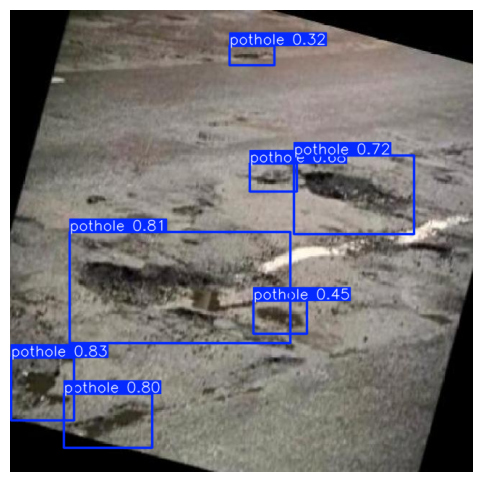

In [14]:
# 19 · Inference — format Label / Confidence seperti notebook BiLSTM
INFERENCE_SKEMA = None  # None = pakai skema dengan mAP50-95 test tertinggi. Isi 'A' atau 'B' untuk memilih sendiri.
if INFERENCE_SKEMA is None:
    INFERENCE_SKEMA = summary.loc[summary['mAP50_95'].idxmax(), 'skema']
print('Inference memakai', RUN_NAMES[INFERENCE_SKEMA])
inference_model = YOLO(str(run_paths(INFERENCE_SKEMA)[1]))
def predict_road(image_path, model, confidence=0.25):
    result = model.predict(source=str(image_path), imgsz=IMG_SIZE, conf=confidence,
                            device=DEVICE, half=False, verbose=False)[0]
    print(f'Gambar    : {image_path}')
    if result.boxes is None or len(result.boxes) == 0:
        print('Label     : Tidak ada kerusakan terdeteksi pada threshold ini')
    else:
        for class_id, score, xyxy in zip(result.boxes.cls.tolist(), result.boxes.conf.tolist(),
                                         result.boxes.xyxy.tolist()):
            print(f'Label     : {result.names[int(class_id)]}')
            print(f'Confidence: {score:.2%}')
            print(f'Bounding box (x1,y1,x2,y2): {[round(v, 1) for v in xyxy]}')
    plt.figure(figsize=(12, 6))
    plt.imshow(result.plot()[..., ::-1])
    plt.axis('off')
    plt.show()
    return result

CONTOH_GAMBAR = X_test[0]   # ganti dengan path gambar jalan milikmu
print('       HASIL INFERENCE MODEL YOLO')
contoh_hasil = predict_road(CONTOH_GAMBAR, inference_model, confidence=PREDICT_CONF)


Setiap skema punya folder sendiri di `MyDrive/deteksi-jalan/hasil/yolo_kaggle_pothole/<RUN_NAME>/`:

| File di folder run Drive | Isi |
|---|---|
| `weights/best.pt`, `weights/last.pt` | Checkpoint YOLO |
| `results.csv`, `results.png` | Riwayat dan grafik training |
| `metrics.csv`, `metrics_per_class.csv` | Metrik test |
| `predictions_test.csv` | Bounding box hasil inferensi |
| `cleaning_audit.csv`, `near_duplicates.csv` | Keputusan cleaning dan kandidat gambar mirip |


Ringkasan A vs B: `MyDrive/deteksi-jalan/hasil/yolo_kaggle_pothole/perbandingan_<model>_<RUN_SUFFIX>.csv`.
